# Proteosim: simulated bottom-up proteomics experiment

This notebook demonstrates the full `proteosim` workflow: reading proteins from a FASTA file, in-silico digestion, sequence coverage, LC retention time prediction and MS1/MS2 spectra simulation.

In [8]:
%load_ext autoreload
%autoreload 2

import proteosim as ps

## 1. Read protein sequences

In [9]:
proteins = ps.read_fasta("../data/sample_proteins.fasta")
len(proteins)

3

## 2. In-silico digestion with trypsin

In [10]:
trypsin = ps.enzyme_cleavage_patterns["Trypsin"]
peptides = ps.digest_protein_collection(proteins, trypsin)
peptides

{'P11802': ['MATSR',
  'YEPVAEIGVGAYGTVYK',
  'DPHSGHFVALK',
  'VPNGGGGGGGLPISTVR',
  'EVALLR',
  'LEAFEHPNVVR',
  'LMDVCATSR',
  'VTLVFEHVDQDLR',
  'TYLDK',
  'APPPGLPAETIK',
  'GLDFLHANCIVHR',
  'DLKPENILVTSGGTVK',
  'LADFGLAR',
  'IYSYQMALTPVVVTLWYR',
  'APEVLLQSTYATPVDMWSVGCIFAEMFR',
  'KPLFCGNSEADQLGK',
  'IFDLIGLPPEDDWPR',
  'DVSLPR',
  'GAFPPR',
  'GPRPVQSVVPEMEESGAQLLLEMLTFNPHK',
  'ISAFR',
  'ALQHSYLHK',
  'DEGNPE'],
 'A0A087WTH1': ['MEDEEK',
  'AVEILGNTEAAHPPSPIR',
  'CCWLR',
  'CLAATSIICGCSCLGVMALVFAIK',
  'SEEAVR'],
 'A0A087WTH5': ['MVIEWERPR',
  'MILSNTTAVTPFLTK',
  'LWQETVQQGGNMSGLAR',
  'SGDGK',
  'LEALYVLMVLGFFGFFTLGIMLSYIR',
  'LEHSNDPFNVYIESNAWQEK',
  'AYVQAR',
  'VLESYR',
  'SCYVVENHLAIEQPNTHLPETKPSP']}

## 3. Sequence coverage of CDK4 (P11802)

In [11]:
ps.compute_sequence_coverage(proteins["P11802"], peptides["P11802"])

92.73927392739274

## 4. Pool peptides from all proteins

In [12]:
pooled_peptides = [] 
for peps in peptides.values(): # loop over pep lists of each prot (ignore prot IDs)
    for pep in peps:
        pooled_peptides.append(pep) # add pep to a flat list
print(f'Total peptides: {len(pooled_peptides)}') # total number of peps across all prots

Total peptides: 37


## 5. LC RT prediction

In [14]:
rt_map = ps.predict_lc_retention_times(pooled_peptides)

rt_map

{'MATSR': 8.9,
 'YEPVAEIGVGAYGTVYK': 42.7,
 'DPHSGHFVALK': 29.0,
 'VPNGGGGGGGLPISTVR': 31.6,
 'EVALLR': 25.5,
 'LEAFEHPNVVR': 33.5,
 'LMDVCATSR': 23.6,
 'VTLVFEHVDQDLR': 41.0,
 'TYLDK': 11.1,
 'APPPGLPAETIK': 29.1,
 'GLDFLHANCIVHR': 47.5,
 'DLKPENILVTSGGTVK': 34.5,
 'LADFGLAR': 29.5,
 'IYSYQMALTPVVVTLWYR': 78.1,
 'APEVLLQSTYATPVDMWSVGCIFAEMFR': 96.2,
 'KPLFCGNSEADQLGK': 28.0,
 'IFDLIGLPPEDDWPR': 51.3,
 'DVSLPR': 14.7,
 'GAFPPR': 16.3,
 'GPRPVQSVVPEMEESGAQLLLEMLTFNPHK': 80.9,
 'ISAFR': 19.9,
 'ALQHSYLHK': 28.5,
 'DEGNPE': -4.0,
 'MEDEEK': -0.7,
 'AVEILGNTEAAHPPSPIR': 43.8,
 'CCWLR': 24.6,
 'CLAATSIICGCSCLGVMALVFAIK': 96.2,
 'SEEAVR': 5.7,
 'MVIEWERPR': 30.9,
 'MILSNTTAVTPFLTK': 51.1,
 'LWQETVQQGGNMSGLAR': 39.4,
 'SGDGK': -3.7,
 'LEALYVLMVLGFFGFFTLGIMLSYIR': 140.2,
 'LEHSNDPFNVYIESNAWQEK': 42.6,
 'AYVQAR': 15.6,
 'VLESYR': 18.4,
 'SCYVVENHLAIEQPNTHLPETKPSP': 54.2}

## 6. Chromatographic profile

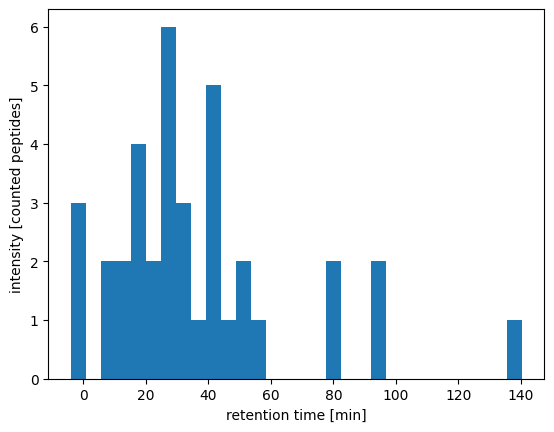

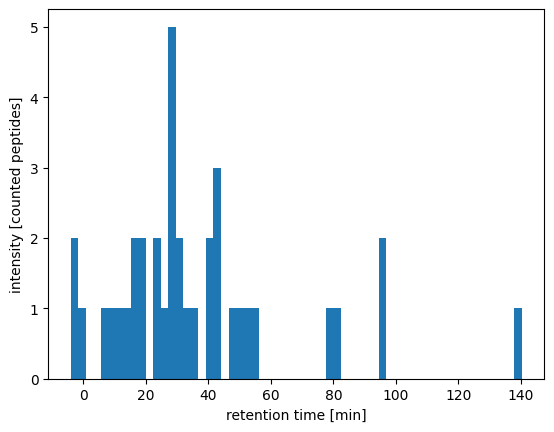

In [15]:
ps.plot_retention_time(rt_map.values())
ps.plot_retention_time(rt_map.values(), resolution=60)

## 7. Select RT window

In [16]:
select_peps = ps.select_retention_time_window(
    peptide_rt_map=rt_map,
    lower_ret_time=0,
    upper_ret_time=20,
)

len(select_peps)

8